# Colocalization with exclusion 10 nm

* Contains the most important colocalization cases

## Initialization

In [1]:
import os
import sys
import itertools
import pathlib

import numpy as np
import scipy as sp
import pandas as pd 

import pyto
from pyto.io.pandas_io import PandasIO
import pyto.spatial.point_pattern as point_pattern
import pyto.spatial.coloc_functions as col_func
import pyto.spatial.coloc_theory as coloc_theory
from pyto.spatial.particle_sets import ParticleSets
from pyto.spatial.multi_particle_sets import MultiParticleSets
from pyto.spatial.coloc_plot import plot_p, plot_32_p, plot_data, plot_32_data, plot_multiple
from pyto.spatial.coloc_lite import ColocLite

# matplotlib 
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

# common
import common
from common import n_A, n_B, n_C
from common import rectangle_full_area

# convenience
#import ipdb
%autosave 0
sys.version

Info: PySeg could not be loaded. This is needed only if Pyto is used to further process PySeg generated files. In this case, calling pyto.spatial.ParticleSetsfrom_pyseg() will fail. Everything else should be fine.


Autosave disabled


'3.11.10 | packaged by conda-forge | (main, Sep 10 2024, 11:01:28) [GCC 13.3.0]'

In [2]:
# Settings

# force showing all rows in a table (default 60 rows)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

# use tex
plt.rcParams['text.usetex'] = True

# np print
np.set_printoptions(legacy='1.25')

# set hostname
hostname = os.uname()[1]
print(f"Host: {hostname}")

Host: rauna


### Setup figures

In [3]:
# Useful functions for figures

# set plot parameters
def set_plot(plot_type):
    
    # for making figures 
    if plot_type == 'figure_save':
        # for some reason need to repeat
        %matplotlib qt
        plt.rcParams['font.size'] = 16  
        %matplotlib qt
        plt.rcParams['font.size'] = 16
        plt.rcParams['lines.linewidth'] =  1
    
    # figure-like inline
    if plot_type == 'figure_inline':
        %matplotlib inline
        plt.rcParams['font.size'] = 16
    
    # standard inline
    if plot_type == 'inline':
        %matplotlib inline
        plt.rcParams["figure.figsize"] = [4.5, 3]


In [4]:
# choose figure type, uncomment one
#plot_type = 'figure_save' 
#plot_type = 'figure_inline'
plot_type = 'inline'

set_plot(plot_type)

# directory to save plots (only if plot_type = 'figure_save')
plot_root = os.path.join(
    pathlib.Path.home(), 
    'text/manuscripts/coloc_method_2024/figures/graphs/exclusion-10/')

## General parameters and definitions

In [5]:
# General params

# path to particles (patterns) table
mps_path = 'particles/mps.pkl'

# colocalization distance [nm]
distance = np.arange(1, 31)

# N simulations
n_simul = 20
#n_simul = 500

# exclusion distance [nm]
exclusion_distance = 10

# colocalization results directory
coloc_dir = f'coloc_exclusion-{exclusion_distance}_{n_simul}'
coloc_dir_500 = f'coloc_exclusion-{exclusion_distance}_500'

# ater exclusion particles dir
mps_excl_dir = f'{coloc_dir}/after_exclusion_particles'

# colocalization name mode
name_mode = '_'

In [6]:
colors = {'A': 'm', 'B': 'c', 'C': 'y'}

def plot_pattern(
    mps, names, ranges=None, x_col=None, y_col=None, legend=True, 
    colors=None, xlim=(100, 500), ylim=(200, 400), ax=None, 
    markersize=5, **plot_kw):
    """Makes one plot that may contain multiple patterns.
    """

    if x_col is None:
        x_col = 'x_reg_frame'
    if y_col is None:
        y_col = 'y_reg_frame'
    if ax is None:
        fig, ax = plt.subplots()
    for ind, nam in enumerate(names):
        if colors is None:
            col = f'C{ind}'
        elif isinstance(colors, (list, tuple)):
            col = colors[ind]
        elif isinstance(colors, dict):
            col = colors[nam[0]]
        if ranges is None or ranges[ind] is None:
            (mps.particles
                .query("subclass_name == @nam")
                .plot(kind='scatter', x=x_col, y=y_col, color=col, 
                      legend=True, ax=ax, s=markersize, **plot_kw)
            )
        else:
            (mps.particles
                .query("subclass_name == @nam")
                .iloc[range(*ranges[ind])]
                .plot(kind='scatter', x=x_col, y=y_col, color=col, 
                      legend=True, ax=ax, s=markersize, **plot_kw)
            )
    if legend:
        ax.legend(names)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel('')
    ax.set_ylabel('')
        
    return ax

## Read particles and glance at them

In [7]:
# read particles
# Has to be executed if the previous section was not executed

mps = MultiParticleSets.read(mps_path)

Read  MPS object particles/mps.pkl


In [8]:
n_part = mps.particles.groupby(['tomo_id', 'subclass_name'])['pixel_nm'].count()
n_part

tomo_id  subclass_name                   
alpha    ARandom05                           300
         ARandom05e                          300
         ARandom05ne                         300
         ARandom05sw                         300
         ARandom05w                          300
         ARandom06                           300
         ARandom06e                          300
         ARandom06ne                         300
         ARandom06sw                         300
         ARandom06w                          300
         ARandom08                           300
         ARandom50                           300
         ARandomExclFull                     300
         ARandomFull                         300
         Ar05CoclustBr05p0.3-p0.3-d10        300
         Ar05CoclustBr05p0.3-p0.3-d5         300
         Ar05CoclustBr05p0.7-p0.7-d10        300
         Ar05CoclustBr05p0.7-p0.7-d5         300
         Ar05CoclustBr05p1-p1-d10            300
         Ar05CoclustBr05p1-

In [9]:
# Check N particles in all patterns
if np.all([eval(f"n_{pattern[0]} == {value}") 
           for (tomo_id, pattern), value in n_part.items()]):
    print("Success: All patterns have correct number of particles")
else:
    print("ERROR: Some patterns have incorrect number of particles")

Success: All patterns have correct number of particles


## Calculate 2-colocalizations

### Random

In [10]:
# Colocalization

# colocalization name
coloc_name = 'ARandomFull_BRandomFull'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandomFull_BRandomFull
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandomFull_BRandomFull/ARandomFull_BRandomFull.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BRandomFull
    tomo_id                                
    alpha                  300          250
    Total                  300          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandomFull_BRandomFull/ARandomFull_BRandomFull.pkl
N particles after exclusion:
    subclass_name  ARandomFull  BRandomFull
    tomo_id                                
    alpha                  190  

In [11]:
# Colocalization

# colocalization name
coloc_name = 'BRandomFull_ARandomFull'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: BRandomFull_ARandomFull
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/BRandomFull_ARandomFull/BRandomFull_ARandomFull.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BRandomFull
    tomo_id                                
    alpha                  300          250
    Total                  300          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/BRandomFull_ARandomFull/BRandomFull_ARandomFull.pkl
N particles after exclusion:
    subclass_name  ARandomFull  BRandomFull
    tomo_id                                
    alpha                  190  

### Univariate

In [12]:
# colocalization name
coloc_name = 'ARandom06_BRandomFull'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandom06_BRandomFull
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandom06_BRandomFull/ARandom06_BRandomFull.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  BRandomFull
    tomo_id                              
    alpha                300          250
    Total                300          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandom06_BRandomFull/ARandom06_BRandomFull.pkl
N particles after exclusion:
    subclass_name  ARandom06  BRandomFull
    tomo_id                              
    alpha                169          175
    Total   

In [13]:
# colocalization name
coloc_name = 'BRandomFull_ARandom06'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: BRandomFull_ARandom06
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/BRandomFull_ARandom06/BRandomFull_ARandom06.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  BRandomFull
    tomo_id                              
    alpha                300          250
    Total                300          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/BRandomFull_ARandom06/BRandomFull_ARandom06.pkl
N particles after exclusion:
    subclass_name  ARandom06  BRandomFull
    tomo_id                              
    alpha                169          175
    Total   

### Global interaction

In [14]:
# colocalization name
coloc_name = 'ARandom06_BRandom06'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandom06_BRandom06
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandom06_BRandom06/ARandom06_BRandom06.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  BRandom06
    tomo_id                            
    alpha                300        250
    Total                300        250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandom06_BRandom06/ARandom06_BRandom06.pkl
N particles after exclusion:
    subclass_name  ARandom06  BRandom06
    tomo_id                            
    alpha                169        138
    Total                169        

In [15]:
# colocalization name
coloc_name = 'BRandom06_ARandom06'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: BRandom06_ARandom06
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/BRandom06_ARandom06/BRandom06_ARandom06.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  BRandom06
    tomo_id                            
    alpha                300        250
    Total                300        250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/BRandom06_ARandom06/BRandom06_ARandom06.pkl
N particles after exclusion:
    subclass_name  ARandom06  BRandom06
    tomo_id                            
    alpha                169        138
    Total                169        

### Local interaction 1-to-1

In [16]:
# colocalization name
coloc_name = 'ARandomFull_BrfCoclustArfp03-pkd-d10'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandomFull_BrfCoclustArfp03-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandomFull_BrfCoclustArfp03-pkd-d10/ARandomFull_BrfCoclustArfp03-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp03-pkd-d10
    tomo_id                                             
    alpha                  300                       250
    Total                  300                       250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandomFull_BrfCoclustArfp03-pkd-d10/ARandomFull_BrfCoclustArfp03-pkd-d10.pkl
N particles after exclusion:
   

In [17]:
# colocalization name
coloc_name = 'BrfCoclustArfp03-pkd-d10_ARandomFull'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: BrfCoclustArfp03-pkd-d10_ARandomFull
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/BrfCoclustArfp03-pkd-d10_ARandomFull/BrfCoclustArfp03-pkd-d10_ARandomFull.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp03-pkd-d10
    tomo_id                                             
    alpha                  300                       250
    Total                  300                       250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/BrfCoclustArfp03-pkd-d10_ARandomFull/BrfCoclustArfp03-pkd-d10_ARandomFull.pkl
N particles after exclusion:
   

### Local 1-to-1 and global interaction

In [18]:
# colocalization name
coloc_name = 'ARandom06_Br06CoclustAr06p015-pkd-d10'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandom06_Br06CoclustAr06p015-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandom06_Br06CoclustAr06p015-pkd-d10/ARandom06_Br06CoclustAr06p015-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  Br06CoclustAr06p015-pkd-d10
    tomo_id                                              
    alpha                300                          250
    Total                300                          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandom06_Br06CoclustAr06p015-pkd-d10/ARandom06_Br06CoclustAr06p015-pkd-d10.pkl
N particles after exclu

In [19]:
# colocalization name
coloc_name = 'Br06CoclustAr06p015-pkd-d10_ARandom06'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: Br06CoclustAr06p015-pkd-d10_ARandom06
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/Br06CoclustAr06p015-pkd-d10_ARandom06/Br06CoclustAr06p015-pkd-d10_ARandom06.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  Br06CoclustAr06p015-pkd-d10
    tomo_id                                              
    alpha                300                          250
    Total                300                          250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/Br06CoclustAr06p015-pkd-d10_ARandom06/Br06CoclustAr06p015-pkd-d10_ARandom06.pkl
N particles after exclu

In [20]:
# colocalization name
coloc_name = 'ARandom06_Br06CoclustAr06p03-pkd-d10'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: ARandom06_Br06CoclustAr06p03-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandom06_Br06CoclustAr06p03-pkd-d10/ARandom06_Br06CoclustAr06p03-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  Br06CoclustAr06p03-pkd-d10
    tomo_id                                             
    alpha                300                         250
    Total                300                         250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/ARandom06_Br06CoclustAr06p03-pkd-d10/ARandom06_Br06CoclustAr06p03-pkd-d10.pkl
N particles after exclusion:
   

In [21]:
# colocalization name
coloc_name = 'Br06CoclustAr06p03-pkd-d10_ARandom06'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization name: Br06CoclustAr06p03-pkd-d10_ARandom06
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/Br06CoclustAr06p03-pkd-d10_ARandom06/Br06CoclustAr06p03-pkd-d10_ARandom06.pkl
N particles initial (before exclusion):
    subclass_name  ARandom06  Br06CoclustAr06p03-pkd-d10
    tomo_id                                             
    alpha                300                         250
    Total                300                         250
Pickled  MPS object to coloc_exclusion-10_20/after_exclusion_particles/Br06CoclustAr06p03-pkd-d10_ARandom06/Br06CoclustAr06p03-pkd-d10_ARandom06.pkl
N particles after exclusion:
   

### 3-coloc local 1-to-1 

In [22]:
# colocalization name
coloc_name = 'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization cases: ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10, ARandomFull_BrfCoclustArfp01k-pkd-d10, ARandomFull_CrfCoclustArfp01k-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp01k-pkd-d10  CrfCoclustArfp01k-pkd-d10
    tomo_id                                                                         
    alpha                  300                        250                      

In [23]:
# colocalization name
coloc_name = 'CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col = ColocLite(dir_=coloc_dir)
col.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization cases: CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10, CrfCoclustArfp01k-pkd-d10_ARandomFull, CrfCoclustArfp01k-pkd-d10_BrfCoclustArfp01k-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_20/input_particles/CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10/CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp01k-pkd-d10  CrfCoclustArfp01k-pkd-d10
    tomo_id                                                                         
    alpha                  300                        250        

In [24]:
# colocalization name
coloc_name = 'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10'
n_simul_local = 500
coloc_dir_local = f'coloc_exclusion-{exclusion_distance}_{n_simul_local}'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col_500 = ColocLite(dir_=coloc_dir_local)
col_500.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul_local, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization cases: ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10, ARandomFull_BrfCoclustArfp01k-pkd-d10, ARandomFull_CrfCoclustArfp01k-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_500/input_particles/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp01k-pkd-d10  CrfCoclustArfp01k-pkd-d10
    tomo_id                                                                         
    alpha                  300                        250                     

In [25]:
# colocalization name
coloc_name = 'CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10'
n_simul_local = 500
coloc_dir_local = f'coloc_exclusion-{exclusion_distance}_{n_simul_local}'

# select particles 
set_names = col_func.get_names(coloc_name, mode=name_mode)
mps_local = mps.select(class_names=set_names, update=False)

# colocalize
col_500 = ColocLite(dir_=coloc_dir_local)
col_500.colocalize(
    coloc_case=coloc_name, particles=mps_local, distance=distance,
    n_simul=n_simul_local, exclusion=exclusion_distance)

Colocalization parameters:
    Colocalization cases: CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10, CrfCoclustArfp01k-pkd-d10_ARandomFull, CrfCoclustArfp01k-pkd-d10_BrfCoclustArfp01k-pkd-d10
    Colocalization distance [nm]: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30 
    Calculate columns: True, columns distance factor 2
    Exclusion distance [nm]: 10
    Make convex hull: False

Tomo pixel size [nm]
    alpha: 1
    bravo: 1
    charlie: 1
Pickled  MPS object to coloc_exclusion-10_500/input_particles/CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10/CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10.pkl
N particles initial (before exclusion):
    subclass_name  ARandomFull  BrfCoclustArfp01k-pkd-d10  CrfCoclustArfp01k-pkd-d10
    tomo_id                                                                         
    alpha                  300                        250       

## Analysis

### Read colocalizations

In [26]:
# Read colocalization results
# has to be executed every time

col = ColocLite.read_table_multi(
    names=None, dir_=coloc_dir, mode=name_mode, verbose=False)
col_500 = ColocLite.read_table_multi(
    names=None, dir_=coloc_dir_500, mode=name_mode, verbose=False)

### Check

In [27]:
col.data_names

['ARandomFull_BrfCoclustArfp03-pkd-d10',
 'Br06CoclustAr06p015-pkd-d10_ARandom06',
 'ARandom06_Br06CoclustAr06p03-pkd-d10',
 'BRandomFull_ARandomFull',
 'CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10',
 'CrfCoclustArfp01k-pkd-d10_ARandomFull',
 'CrfCoclustArfp01k-pkd-d10_BrfCoclustArfp01k-pkd-d10',
 'BrfCoclustArfp03-pkd-d10_ARandomFull',
 'ARandom06_BRandom06',
 'BRandom06_ARandom06',
 'ARandomFull_BRandomFull',
 'ARandom06_BRandomFull',
 'BRandomFull_ARandom06',
 'Br06CoclustAr06p03-pkd-d10_ARandom06',
 'ARandom06_Br06CoclustAr06p015-pkd-d10',
 'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10',
 'ARandomFull_CrfCoclustArfp01k-pkd-d10',
 'ARandomFull_BrfCoclustArfp01k-pkd-d10']

In [28]:
col_500.data_names

['CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10',
 'CrfCoclustArfp01k-pkd-d10_ARandomFull',
 'CrfCoclustArfp01k-pkd-d10_BrfCoclustArfp01k-pkd-d10',
 'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10',
 'ARandomFull_CrfCoclustArfp01k-pkd-d10',
 'ARandomFull_BrfCoclustArfp01k-pkd-d10']

### Random

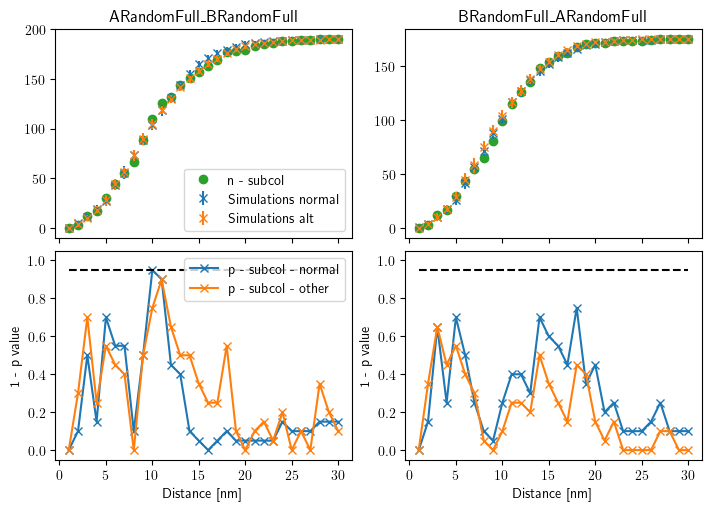

In [29]:
names = ['ARandomFull_BRandomFull', 'BRandomFull_ARandomFull']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'Arf-Brf.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandomFull_BRandomFull/ARandomFull_BRandomFull.pkl


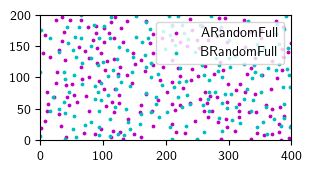

In [30]:
# plot particles

name = 'ARandomFull_BRandomFull'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'Arf-Brf_particles.pdf', bbox_inches='tight')

### Univariate

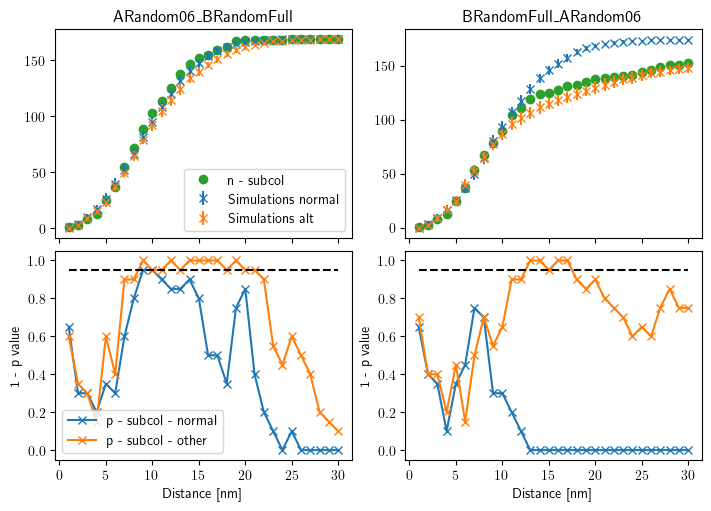

In [31]:
names = ['ARandom06_BRandomFull', 'BRandomFull_ARandom06']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'A06-Brf.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandom06_BRandomFull/ARandom06_BRandomFull.pkl


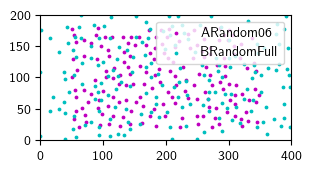

In [32]:
# plot particles

name = 'ARandom06_BRandomFull'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'A06-Brf_particles.pdf', bbox_inches='tight')

### Global interaction

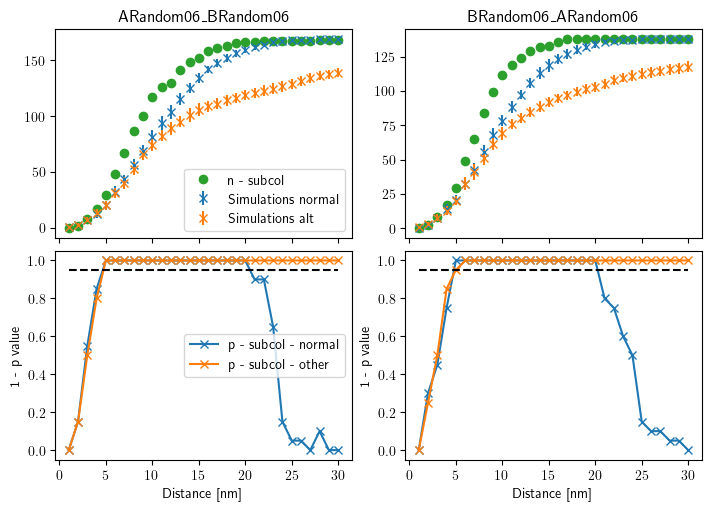

In [33]:
names = ['ARandom06_BRandom06', 'BRandom06_ARandom06']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'A06-B06.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandom06_BRandom06/ARandom06_BRandom06.pkl


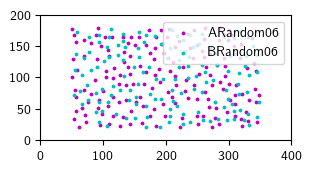

In [34]:
# plot particles

name = 'ARandom06_BRandom06'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'A06-B06_particles.pdf', bbox_inches='tight')

In [35]:
(mps_excl.particles.query("class_name == 'ARandom06'").shape,
 mps_excl.particles.query("class_name == 'BRandom06'").shape)

((169, 8), (138, 8))

### Local interaction 1-to-1

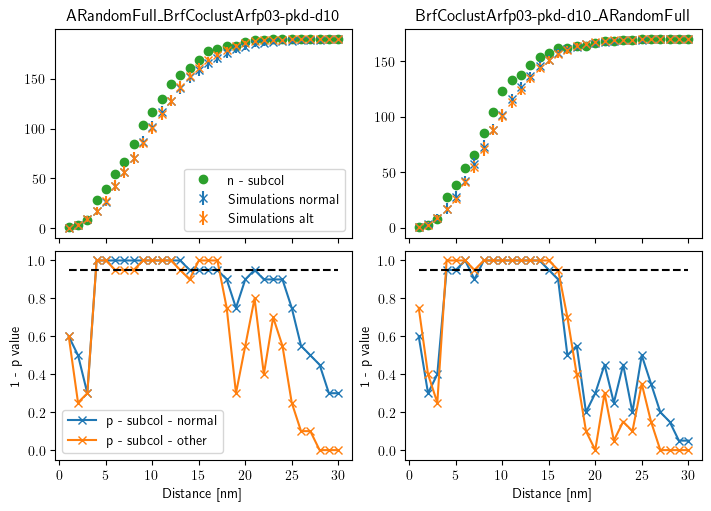

In [36]:
names = ['ARandomFull_BrfCoclustArfp03-pkd-d10',
         'BrfCoclustArfp03-pkd-d10_ARandomFull']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'Arf_Bp03kd.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandomFull_BrfCoclustArfp03-pkd-d10/ARandomFull_BrfCoclustArfp03-pkd-d10.pkl


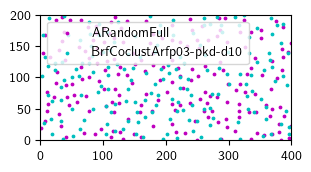

In [37]:
# plot particles

name = 'ARandomFull_BrfCoclustArfp03-pkd-d10'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'Arf_Bp03kd_particles.pdf', bbox_inches='tight')

### Local 1-to-1 and global interaction

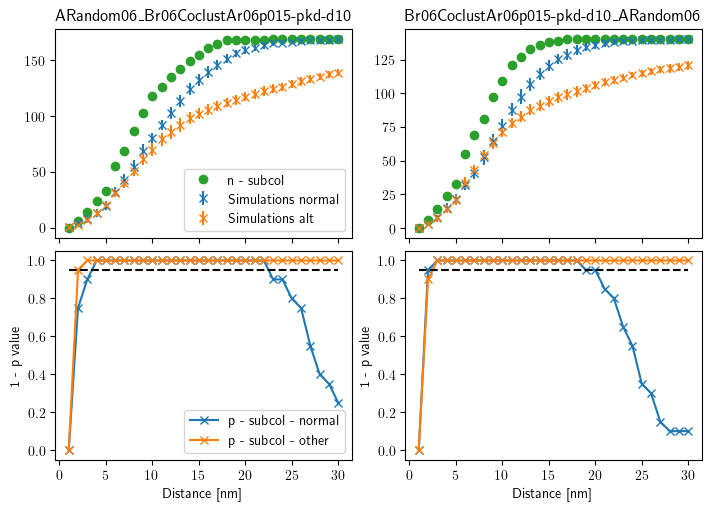

In [38]:
names = ['ARandom06_Br06CoclustAr06p015-pkd-d10',
        'Br06CoclustAr06p015-pkd-d10_ARandom06']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'A06_B06p015kd.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandom06_Br06CoclustAr06p015-pkd-d10/ARandom06_Br06CoclustAr06p015-pkd-d10.pkl


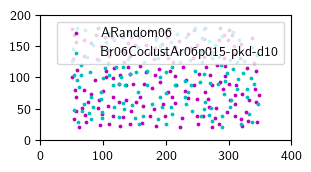

In [39]:
# plot particles

name = 'ARandom06_Br06CoclustAr06p015-pkd-d10'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'A06_B06p015kd_particles.pdf', bbox_inches='tight')

### 3-coloc local 1-to-1, common subsets 

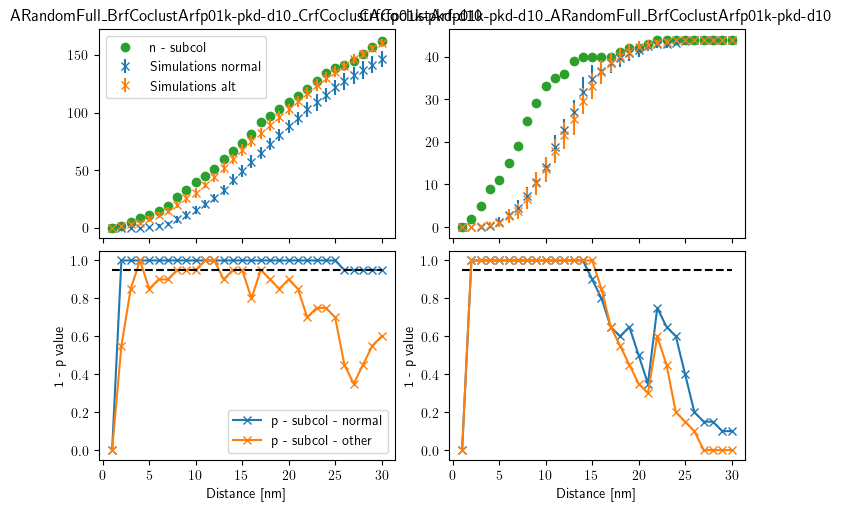

In [40]:
names = [
    'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10',
    'CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'Arf_Bp01kpkd_Cp01kpkd.svg')

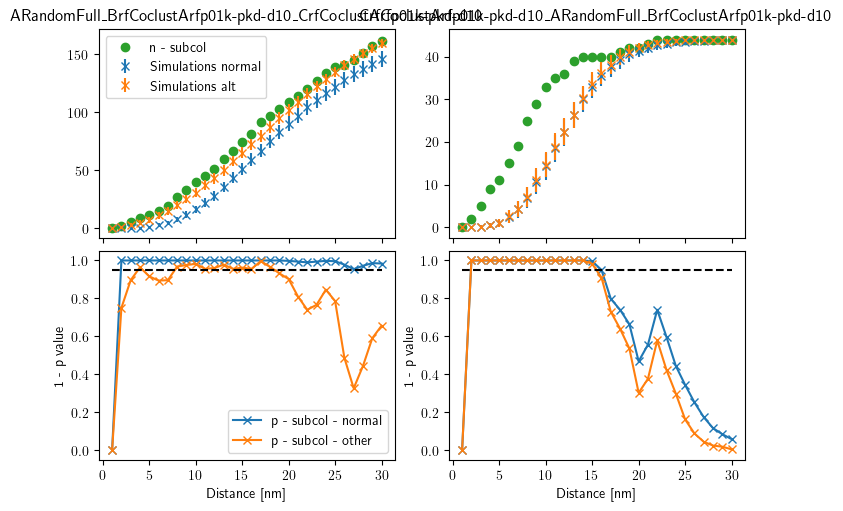

In [41]:
# 500 simul
names = [
    'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10',
    'CrfCoclustArfp01k-pkd-d10_ARandomFull_BrfCoclustArfp01k-pkd-d10']
tomos = None
single = False
normalize = False

n_columns = 2
fig_width = 7
fig_height_one = 2.5

fig, axes = plot_multiple(
    coloc=col_500, names=names, normalize=normalize, n_columns=n_columns, fig_width=fig_width, 
    fig_height_one=fig_height_one, tomos=tomos, single=single, names_inner=True);
#axes[0, 1].set_title('');

if plot_type == 'figure_save':
    axes[0, 0].set_title('')
    axes[0, 1].set_title('')
    axes[0, 0].set_ylabel('N colocalizations')
    axes[1, 1].set_ylabel('')
    axes[0, 0].get_legend().remove()
    #axes[0, 1].get_legend().remove()
    axes[1, 0].get_legend().remove()
    plt.savefig(plot_root + 'Arf_Bp01kpkd_Cp01kpkd_500.svg')

Read  MPS object coloc_exclusion-10_20/after_exclusion_particles/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10/ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10.pkl


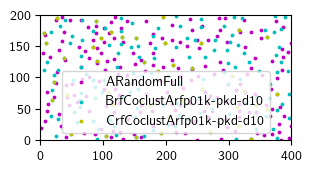

In [42]:
# plot particles

name = 'ARandomFull_BrfCoclustArfp01k-pkd-d10_CrfCoclustArfp01k-pkd-d10'
pattern_name = name.split('_')

# read particles
mps_path_excl = os.path.join(mps_excl_dir, name, f'{name}.pkl')
mps_excl = MultiParticleSets.read(mps_path_excl)

xlim=(100, 500)
ylim=(200, 400)
fig, ax = plt.subplots(1, 1, figsize=(3, 2.), layout='constrained')
_ = plot_pattern(
    mps=mps_excl, names=pattern_name, ax=ax, xlim=xlim, ylim=ylim,
    colors=colors, markersize=3)
    
ax.set_xticks(ax.get_xticks(), ax.get_xticks().astype(int) - xlim[0])
ax.set_yticks(ax.get_yticks(), ax.get_yticks().astype(int) - ylim[0])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect('equal', adjustable='box')

if plot_type == 'figure_save':
    ax.get_legend().remove()
    plt.savefig(
        plot_root + 'Arf_Bp01kpkd_Cp01kpkd_particles.pdf', bbox_inches='tight')